## XGBoost Forecasting of *Karenia brevis* Conditions (Sarasota)

This notebook forecasts the weekly *K. brevis* class (0, 1, 2) one, two and four weeks ahead from the merged weekly Sarasota dataset. Class 1 is the rare middle class: about 8% of labelled weeks.

**What changed from the first version**

| Area | First version | This version |
| --- | --- | --- |
| Reference point | None | **Persistence baseline** (predict the last observed class), which any model must beat |
| Hyperparameters | `XGBClassifier()` defaults for every horizon | Settings **tuned separately for each horizon** |
| Class imbalance | None | Training **without weights, with fully balanced weights, and with softened (square-root) weights** |
| Features | All 85, or the fold's top 15 | Six **feature subsets**, plus new **lagged environmental variables** |
| Validation | Mean of per-year accuracy and macro-F1 | **Forward-chaining** by bloom year, scored by **pooled macro-F1** over a fixed label set, plus per-class recall |
| Model selection | n/a | **Nested** forward-chaining: each test year's configuration is chosen using earlier years only |
| Reproducibility | Unseeded | Fixed seed and a cached search |

**Why pooled macro-F1?** Several test years are tiny or contain a single class: 2022 has 4 labelled weeks, 2023 has 11, and 2024 and 2026 are all class 0. Per-year macro-F1 then jumps between 0 and 1 for reasons unrelated to model skill. Pooling every out-of-fold prediction for a horizon, and scoring against all three classes, gives a much steadier number. The per-year mean is still reported so results stay comparable with the first version.

### Setup

In [1]:
# !pip install xgboost

In [2]:
import os
import json
import hashlib
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from joblib import Parallel, delayed
from sklearn.metrics import accuracy_score, f1_score, recall_score, confusion_matrix
from sklearn.model_selection import ParameterSampler
from xgboost import XGBClassifier

try:
    from IPython.display import display
except ImportError:  # running as a plain script
    display = print

warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)

SEED = 42
HORIZONS = [1, 2, 4]
CLASSES = [0, 1, 2]
TEST_YEARS = list(range(2016, 2027))     # reported (outer) folds, same as the first version
CACHE_YEARS = list(range(2013, 2027))    # 2013-2015 are used only for inner model selection
N_HP_CONFIGS = 10                        # sampled hyperparameter sets (plus the defaults)
N_JOBS = -1                              # parallel fits; lower this if memory is tight

### Load the Weekly Dataset

In Colab this mounts Google Drive. Run locally, it reads `merged_weekly_sarasota.csv` from the working directory.

In [3]:
try:
    from google.colab import drive
    drive.mount("/content/drive")
    DATA_DIR = "/content/drive/MyDrive/data"
    os.chdir(DATA_DIR)
    DATA_PATH = "merged/merged_weekly_sarasota.csv"
except ImportError:
    DATA_PATH = "merged/merged_weekly_sarasota.csv"
    if not os.path.exists(DATA_PATH):
        DATA_PATH = "merged_weekly_sarasota.csv"

RESULTS_DIR = "results"
os.makedirs(RESULTS_DIR, exist_ok=True)

dataset = pd.read_csv(DATA_PATH, parse_dates=["week_ending"])
dataset = dataset.sort_values("week_ending").reset_index(drop=True)

TARGETS = [f"target_{h}w" for h in HORIZONS]
print(dataset.shape, dataset["week_ending"].min().date(), "to", dataset["week_ending"].max().date())

# The lag features below rely on one row per week with no gaps
gaps = dataset["week_ending"].diff().dropna().dt.days
assert (gaps == 7).all(), "Weekly series has gaps; lag features would be misaligned"

(853, 89) 2010-01-03 to 2026-05-03


### Data Checks

Count each class per bloom year and check for missing values. Columns that are entirely empty carry no information and are dropped.

In [4]:
bloom_year = dataset["week_ending"].dt.year + (dataset["week_ending"].dt.month >= 8)
print("target_1w class counts by bloom year (Aug-Jul):")
display(pd.crosstab(bloom_year, dataset["target_1w"]).rename_axis(index="bloom_year"))

missing = dataset.isna().mean().sort_values(ascending=False)
print("Most-missing columns (fraction missing):")
display(missing.head(12).round(3).to_frame("frac_missing"))

all_missing = missing[missing == 1.0].index.tolist()
print("Dropping fully-missing columns:", all_missing)
dataset = dataset.drop(columns=all_missing)

target_1w class counts by bloom year (Aug-Jul):


target_1w,0.0,1.0,2.0
bloom_year,,,
2010,30,0,0
2011,53,0,0
2012,49,1,2
2013,23,7,22
2014,48,2,2
2015,52,0,0
2016,22,12,19
2017,18,6,28
2018,29,9,14


Most-missing columns (fraction missing):


,frac_missing
bay_tss_8w,1.000
creek_chl_uncorr_8w,0.816
mote_water_temp_c,0.776
wind_u_4w,0.768
wind_v_4w,0.768
wind_u,0.767
wind_v,0.767
pressure_mb,0.767
wind_speed,0.767
ksrq_air_temp_c,0.767


Dropping fully-missing columns: ['bay_tss_8w']


### Lagged Environmental Variables

The merged data already contains *K. brevis* lags and 8-week nutrient windows. What it lacks is **lagged physical and environmental drivers**: conditions 2, 4 and 8 weeks before the forecast origin, plus 4-week changes. Blooms can respond to upwelling winds, temperature, runoff and nutrients with a delay, so these lags may add lead time.

The lags use `shift(k)` on the gap-free weekly series, so each row sees only past values and nothing leaks from the future.

In [5]:
LAG_VARS = [
    "water_temp_c", "chl_mean_log", "chl_anomaly", "chl_coastal_anomaly", "chl_p90",
    "habsos_salinity", "rain_in_4w", "wind_v_4w", "wind_u_4w", "grid_uwnd_4w",
    "air_temp_f", "bay_po4_8w", "bay_tn_8w", "creek_nox_8w", "creek_po4_8w",
]
LAGS = [2, 4, 8]

lag_frames = {}
for var in LAG_VARS:
    for k in LAGS:
        lag_frames[f"{var}_lag{k}"] = dataset[var].shift(k)
    lag_frames[f"{var}_chg4w"] = dataset[var] - dataset[var].shift(4)

lag_df = pd.DataFrame(lag_frames)
ENV_LAG_COLS = lag_df.columns.tolist()
dataset = pd.concat([dataset, lag_df], axis=1)
print(f"Added {len(ENV_LAG_COLS)} lagged environmental features")

Added 60 lagged environmental features


### Feature Subsets

Columns are grouped by data source, and six subsets are compared. Every subset includes the *K. brevis* history, since it is by far the strongest signal.

In [6]:
original_cols = [c for c in dataset.columns
                 if c not in ["week_ending"] + TARGETS + ENV_LAG_COLS]

KB_COLS = [c for c in original_cols
           if c.startswith(("kb_", "rkb_"))
           or c in ["last_class", "weeks_since_sample", "weeks_since_bloom"]]
SEASON_COLS = ["woy_sin", "woy_cos"]
CHL_COLS = [c for c in original_cols if c.startswith("chl_")]
NUTRIENT_COLS = [c for c in original_cols if c.startswith(("bay_", "creek_"))]
PHYSICAL_COLS = [c for c in original_cols
                 if c not in KB_COLS + SEASON_COLS + CHL_COLS + NUTRIENT_COLS]

FEATURE_SETS = {
    "kb_only":          KB_COLS + SEASON_COLS,
    "kb_physical":      KB_COLS + SEASON_COLS + PHYSICAL_COLS + CHL_COLS,
    "kb_physical_lags": KB_COLS + SEASON_COLS + PHYSICAL_COLS + CHL_COLS + ENV_LAG_COLS,
    "kb_nutrients":     KB_COLS + SEASON_COLS + NUTRIENT_COLS,
    "all":              original_cols,
    "all_lags":         original_cols + ENV_LAG_COLS,
}

# Sanity check: every original column is in exactly one group
assert sorted(KB_COLS + SEASON_COLS + CHL_COLS + NUTRIENT_COLS + PHYSICAL_COLS) == sorted(original_cols)

display(pd.DataFrame({"n_features": {k: len(v) for k, v in FEATURE_SETS.items()}}))
print("Physical columns:", PHYSICAL_COLS)

,n_features
kb_only,25
kb_physical,54
kb_physical_lags,114
kb_nutrients,55
all,84
all_lags,144


Physical columns: ['mote_water_temp_c', 'habsos_water_temp_c', 'habsos_salinity', 'water_temp_c', 'water_temp_change_2w', 'warm_weeks_8w', 'air_temp_f', 'air_temp_max_f', 'rain_in_1w', 'rain_in_4w', 'rain_in_8w', 'rain_in_12w', 'wind_u', 'wind_v', 'wind_speed', 'wind_v_4w', 'wind_u_4w', 'ksrq_air_temp_c', 'pressure_mb', 'grid_uwnd', 'grid_uwnd_4w']


### Forward-Chaining Folds and Metrics

Folds are the same as in the first version. Bloom year *Y* covers forecast-origin weeks from Aug 1 of *Y−1* up to Aug 1 of *Y*. The model trains only on rows whose **target date** falls before the test period starts, so no label from the test period can enter training.

Metrics:
* **Pooled macro-F1** (primary): F1 averaged over classes 0, 1 and 2, computed on every out-of-fold prediction for the horizon at once.
* **Mean per-year macro-F1** and **accuracy**: the first version's metrics, kept for comparison.
* **Recall and F1 for classes 1 and 2**: how well blooms are actually detected.

In [7]:
def horizon_data(horizon):
    """Rows with a known target for this horizon, plus the date the target refers to."""
    target = f"target_{horizon}w"
    data = dataset.dropna(subset=[target]).copy()
    data[target] = data[target].astype(int)
    data["target_week"] = data["week_ending"] + pd.to_timedelta(7 * horizon, unit="D")
    return data, target


def make_folds(data, target, years):
    """Forward-chaining folds by Aug-Jul bloom year."""
    folds = []
    for year in years:
        test_start = pd.Timestamp(year=year - 1, month=8, day=1)
        test_end = pd.Timestamp(year=year, month=8, day=1)
        test_idx = data.index[(data["week_ending"] >= test_start) & (data["week_ending"] < test_end)]
        train_idx = data.index[data["target_week"] < test_start]
        if len(test_idx) == 0:
            continue
        # XGBoost needs every class present in training to keep labels 0..2 aligned
        if set(data.loc[train_idx, target].unique()) != set(CLASSES):
            continue
        folds.append((year, train_idx, test_idx))
    return folds


def score(y_true, y_pred):
    """Pooled metrics over a fixed label set so rare classes always count."""
    f1s = f1_score(y_true, y_pred, labels=CLASSES, average=None, zero_division=0)
    recalls = recall_score(y_true, y_pred, labels=CLASSES, average=None, zero_division=0)
    return {
        "macro_f1": f1s.mean(),
        "accuracy": accuracy_score(y_true, y_pred),
        "f1_c1": f1s[1], "f1_c2": f1s[2],
        "recall_c1": recalls[1], "recall_c2": recalls[2],
    }


def mean_fold_macro_f1(df):
    """The first version's metric: macro-F1 per test year, then averaged."""
    return df.groupby("test_year").apply(
        lambda g: f1_score(g["y_true"], g["y_pred"], average="macro", zero_division=0),
        include_groups=False,
    ).mean()


def summarize(pred_df):
    """Pooled metrics over the reported test years plus the per-year mean."""
    p = pred_df[pred_df["test_year"].isin(TEST_YEARS)]
    out = score(p["y_true"], p["y_pred"])
    out["mean_year_macro_f1"] = mean_fold_macro_f1(p)
    out["n"] = len(p)
    return out

### Class Weighting

* `none`: every week counts equally (the first version).
* `balanced`: each class gets total weight inversely proportional to its frequency, as in sklearn's `"balanced"` option.
* `sqrt`: the square root of the balanced weights. This is a milder correction that often keeps precision on the majority class while still lifting rare-class recall.

In [8]:
def sample_weights(y, scheme):
    if scheme == "none":
        return None
    counts = y.value_counts()
    w = len(y) / (len(counts) * counts)
    if scheme == "sqrt":
        w = np.sqrt(w)
    weights = y.map(w).to_numpy(dtype=float)
    return weights / weights.mean()

### Reference Results: Persistence and the First Version's Models

The first version's two models (default XGBoost on all features, and on each fold's top 15) are rerun here with the new metrics. The **persistence** forecast, which repeats `last_class`, sets the bar to beat.

In [9]:
BASE_PARAMS = dict(
    objective="multi:softprob", eval_metric="mlogloss", tree_method="hist",
    random_state=SEED, n_jobs=1,
)


def fit_predict(params, feats, weighting, data, target, train_idx, test_idx):
    X_train = data.loc[train_idx, feats]
    y_train = data.loc[train_idx, target]
    model = XGBClassifier(**BASE_PARAMS, **params)
    model.fit(X_train, y_train, sample_weight=sample_weights(y_train, weighting))
    return model, model.predict(data.loc[test_idx, feats])


def fold_frame(data, target, year, test_idx, y_pred, **meta):
    return pd.DataFrame({
        "test_year": year,
        "row": test_idx,
        "target_week": data.loc[test_idx, "target_week"].to_numpy(),
        "y_true": data.loc[test_idx, target].to_numpy(),
        "y_pred": np.asarray(y_pred).astype(int),
        **meta,
    })


reference_preds = []
for horizon in HORIZONS:
    data, target = horizon_data(horizon)
    for year, train_idx, test_idx in make_folds(data, target, TEST_YEARS):
        # Persistence: the forecast is the last observed class
        reference_preds.append(fold_frame(
            data, target, year, test_idx, data.loc[test_idx, "last_class"],
            horizon=horizon, model="Persistence (last_class)"))

        # First version, model 1: defaults on all original features
        base_model, pred = fit_predict({}, original_cols, "none", data, target, train_idx, test_idx)
        reference_preds.append(fold_frame(data, target, year, test_idx, pred,
                                          horizon=horizon, model="Default XGBoost, all features"))

        # First version, model 2: refit on this fold's top-15 features
        top15 = (pd.Series(base_model.feature_importances_, index=original_cols)
                 .nlargest(15).index.tolist())
        _, pred = fit_predict({}, top15, "none", data, target, train_idx, test_idx)
        reference_preds.append(fold_frame(data, target, year, test_idx, pred,
                                          horizon=horizon, model="Default XGBoost, fold top-15"))

reference_preds = pd.concat(reference_preds, ignore_index=True)

reference_summary = pd.DataFrame([
    {"horizon": h, "model": m, **summarize(g)}
    for (h, m), g in reference_preds.groupby(["horizon", "model"])
])
display(reference_summary.round(3))

,horizon,model,macro_f1,accuracy,f1_c1,f1_c2,recall_c1,recall_c2,mean_year_macro_f1,n
0,1,"Default XGBoost, all features",0.607,0.826,0.098,0.820,0.06,0.847,0.559,448
1,1,"Default XGBoost, fold top-15",0.587,0.828,0.037,0.824,0.02,0.831,0.619,448
2,1,Persistence (last_class),0.708,0.833,0.360,0.856,0.36,0.856,0.722,448
3,2,"Default XGBoost, all features",0.544,0.770,0.065,0.703,0.04,0.653,0.551,447
4,2,"Default XGBoost, fold top-15",0.514,0.740,0.031,0.670,0.02,0.627,0.458,447
5,2,Persistence (last_class),0.652,0.790,0.280,0.797,0.28,0.797,0.670,447
6,4,"Default XGBoost, all features",0.509,0.735,0.033,0.670,0.02,0.593,0.517,445
7,4,"Default XGBoost, fold top-15",0.512,0.728,0.059,0.645,0.04,0.585,0.496,445
8,4,Persistence (last_class),0.600,0.744,0.238,0.712,0.24,0.703,0.599,445


### Search Space

Each horizon is searched over the same grid of **feature subset × class weighting × hyperparameters**. Nothing is chosen at this stage: the forward-chaining predictions for every configuration and fold are computed once and cached, and the selection happens later, separately for each horizon.

The hyperparameters favour shallow, regularized trees because the training set is small: 200–700 weeks with only 60 class-1 examples in total.

In [10]:
param_space = {
    "n_estimators": [100, 200, 300, 500],
    "learning_rate": [0.02, 0.05, 0.1],
    "max_depth": [2, 3, 4, 5],
    "min_child_weight": [1, 3, 5],
    "subsample": [0.7, 0.85, 1.0],
    "colsample_bytree": [0.4, 0.6, 0.8, 1.0],
    "reg_lambda": [1, 5, 10],
    "gamma": [0, 0.5, 1.0],
}
HP_CONFIGS = [{}] + list(ParameterSampler(param_space, n_iter=N_HP_CONFIGS, random_state=SEED))

CONFIGS = []
for fs in FEATURE_SETS:
    for weighting in ["none", "sqrt", "balanced"]:
        for hp_id, params in enumerate(HP_CONFIGS):
            CONFIGS.append({
                "config_id": f"{fs}|{weighting}|hp{hp_id}",
                "feature_set": fs, "weighting": weighting, "hp_id": hp_id, "params": params,
            })

hp_table = pd.DataFrame(HP_CONFIGS).rename_axis("hp_id")
display(hp_table.astype(object).fillna("default"))
print(f"{len(CONFIGS)} configurations per horizon")

,subsample,reg_lambda,n_estimators,min_child_weight,max_depth,learning_rate,gamma,colsample_bytree
hp_id,,,,,,,,
0,default,default,default,default,default,default,default,default
1,0.85,10.0,500.0,1.0,5.0,0.05,1.0,0.6
2,1.0,5.0,500.0,5.0,5.0,0.05,0.0,0.4
3,1.0,10.0,300.0,5.0,3.0,0.02,0.5,0.6
4,1.0,10.0,300.0,1.0,2.0,0.05,0.5,1.0
5,0.85,10.0,100.0,1.0,2.0,0.02,0.5,0.6
6,0.7,5.0,200.0,5.0,4.0,0.02,0.0,1.0
7,0.85,10.0,200.0,3.0,2.0,0.1,1.0,0.8
8,0.85,1.0,200.0,1.0,3.0,0.05,0.5,0.6


198 configurations per horizon


### Run the Forward-Chaining Search

This trains every configuration on every fold (2013–2026) for every horizon. The predictions are cached in `results/`, so later runs load them instead of retraining. On a 12-core laptop it takes several minutes; on a free Colab instance expect it to take much longer. Lower `N_HP_CONFIGS` for a quicker run.

In [11]:
def run_config_fold(cfg, horizon, data, target, year, train_idx, test_idx):
    _, pred = fit_predict(cfg["params"], FEATURE_SETS[cfg["feature_set"]], cfg["weighting"],
                          data, target, train_idx, test_idx)
    return fold_frame(data, target, year, test_idx, pred,
                      horizon=horizon, config_id=cfg["config_id"])


cache_key = hashlib.md5(json.dumps(
    [CONFIGS, CACHE_YEARS, HORIZONS, {k: v for k, v in FEATURE_SETS.items()}, SEED,
     len(dataset)], sort_keys=True, default=str).encode()).hexdigest()[:10]
cache_path = os.path.join(RESULTS_DIR, f"xgb_search_preds_{cache_key}.csv.gz")

if os.path.exists(cache_path):
    search_preds = pd.read_csv(cache_path, parse_dates=["target_week"])
    print("Loaded cached search predictions:", cache_path)
else:
    jobs = []
    for horizon in HORIZONS:
        data, target = horizon_data(horizon)
        for year, train_idx, test_idx in make_folds(data, target, CACHE_YEARS):
            for cfg in CONFIGS:
                jobs.append(delayed(run_config_fold)(cfg, horizon, data, target,
                                                     year, train_idx, test_idx))
    print(f"Training {len(jobs)} models ...")
    search_preds = pd.concat(Parallel(n_jobs=N_JOBS, verbose=1)(jobs), ignore_index=True)
    search_preds.to_csv(cache_path, index=False)
    print("Saved:", cache_path)

cfg_meta = pd.DataFrame(CONFIGS).drop(columns="params").set_index("config_id")

Loaded cached search predictions: results\xgb_search_preds_3d651a1894.csv.gz


### Leaderboard: All Configurations on the 2016–2026 Folds

This shows how each configuration did over the reported test years. **Choosing the top row after looking at these test years would be optimistically biased**, so the honest estimate comes from the nested selection in the next section. The leaderboard is still useful for seeing which factors matter.

In [12]:
def config_scores(preds):
    rows = []
    for (h, cid), g in preds.groupby(["horizon", "config_id"]):
        rows.append({"horizon": h, "config_id": cid, **summarize(g)})
    return pd.DataFrame(rows).join(cfg_meta, on="config_id")


leaderboard = config_scores(search_preds)

for horizon in HORIZONS:
    print(f"\n{horizon}-week horizon: top 8 configurations by pooled macro-F1")
    display(leaderboard[leaderboard["horizon"] == horizon]
            .nlargest(8, "macro_f1")
            [["config_id", "macro_f1", "mean_year_macro_f1", "accuracy", "recall_c1", "recall_c2"]]
            .round(3).reset_index(drop=True))


1-week horizon: top 8 configurations by pooled macro-F1


,config_id,macro_f1,mean_year_macro_f1,accuracy,recall_c1,recall_c2
0,kb_only|balanced|hp9,0.676,0.573,0.808,0.32,0.805
1,kb_only|balanced|hp5,0.664,0.559,0.792,0.34,0.814
2,kb_only|sqrt|hp1,0.659,0.567,0.812,0.24,0.822
3,all|balanced|hp9,0.658,0.578,0.830,0.18,0.847
4,kb_only|sqrt|hp9,0.658,0.575,0.812,0.24,0.814
5,kb_only|sqrt|hp6,0.656,0.554,0.815,0.22,0.839
6,kb_only|balanced|hp10,0.656,0.576,0.795,0.30,0.788
7,all|balanced|hp6,0.652,0.568,0.817,0.20,0.864



2-week horizon: top 8 configurations by pooled macro-F1


,config_id,macro_f1,mean_year_macro_f1,accuracy,recall_c1,recall_c2
0,kb_physical_lags|balanced|hp6,0.612,0.570,0.783,0.16,0.822
1,all_lags|balanced|hp5,0.610,0.548,0.761,0.20,0.839
2,kb_physical_lags|balanced|hp0,0.606,0.594,0.801,0.10,0.822
3,kb_physical_lags|balanced|hp5,0.603,0.544,0.740,0.24,0.831
4,kb_physical_lags|balanced|hp3,0.601,0.566,0.767,0.16,0.814
5,kb_physical_lags|balanced|hp10,0.600,0.562,0.783,0.12,0.822
6,kb_nutrients|balanced|hp5,0.600,0.577,0.761,0.18,0.797
7,all|balanced|hp5,0.599,0.573,0.756,0.18,0.822



4-week horizon: top 8 configurations by pooled macro-F1


,config_id,macro_f1,mean_year_macro_f1,accuracy,recall_c1,recall_c2
0,kb_nutrients|balanced|hp9,0.588,0.560,0.773,0.12,0.686
1,kb_nutrients|balanced|hp0,0.585,0.540,0.769,0.12,0.669
2,kb_nutrients|sqrt|hp10,0.577,0.571,0.771,0.10,0.653
3,kb_nutrients|balanced|hp10,0.573,0.568,0.764,0.10,0.669
4,kb_nutrients|sqrt|hp2,0.573,0.572,0.766,0.10,0.644
5,kb_nutrients|sqrt|hp7,0.573,0.571,0.766,0.10,0.653
6,kb_nutrients|balanced|hp8,0.572,0.578,0.764,0.10,0.661
7,kb_nutrients|none|hp0,0.569,0.525,0.766,0.10,0.602


### Effect of Class Weighting and Feature Subsets

Each cell is the **median** pooled macro-F1 over the 11 hyperparameter sets. Using the median, rather than the best, shows a factor's typical effect instead of a lucky draw.

In [13]:
for horizon in HORIZONS:
    lb = leaderboard[leaderboard["horizon"] == horizon]
    print(f"\n{horizon}-week: median pooled macro-F1 (rows = feature subset, columns = weighting)")
    display(lb.pivot_table(index="feature_set", columns="weighting", values="macro_f1",
                           aggfunc="median")[["none", "sqrt", "balanced"]].round(3))

weight_effect = (leaderboard.groupby(["horizon", "weighting"])
                 [["macro_f1", "accuracy", "recall_c1", "f1_c1", "recall_c2"]]
                 .median().round(3))
print("\nClass weighting, median over all feature subsets and hyperparameter sets:")
display(weight_effect)


1-week: median pooled macro-F1 (rows = feature subset, columns = weighting)


weighting,none,sqrt,balanced
feature_set,,,
all,0.601,0.617,0.620
all_lags,0.572,0.601,0.608
kb_nutrients,0.593,0.603,0.613
kb_only,0.618,0.643,0.639
kb_physical,0.621,0.628,0.626
kb_physical_lags,0.568,0.588,0.613



2-week: median pooled macro-F1 (rows = feature subset, columns = weighting)


weighting,none,sqrt,balanced
feature_set,,,
all,0.535,0.550,0.577
all_lags,0.539,0.559,0.586
kb_nutrients,0.527,0.541,0.558
kb_only,0.559,0.565,0.563
kb_physical,0.556,0.566,0.580
kb_physical_lags,0.551,0.566,0.585



4-week: median pooled macro-F1 (rows = feature subset, columns = weighting)


weighting,none,sqrt,balanced
feature_set,,,
all,0.518,0.528,0.536
all_lags,0.504,0.525,0.527
kb_nutrients,0.525,0.554,0.566
kb_only,0.514,0.517,0.532
kb_physical,0.511,0.507,0.517
kb_physical_lags,0.516,0.522,0.520



Class weighting, median over all feature subsets and hyperparameter sets:


macro_f1  accuracy  recall_c1  f1_c1  recall_c2
horizon weighting                                                 
1       balanced      0.619     0.795       0.16  0.190      0.831
        none          0.593     0.819       0.04  0.070      0.839
        sqrt          0.615     0.815       0.10  0.139      0.835
2       balanced      0.574     0.764       0.09  0.107      0.780
        none          0.545     0.783       0.00  0.000      0.725
        sqrt          0.559     0.779       0.03  0.043      0.754
4       balanced      0.529     0.722       0.05  0.064      0.708
        none          0.514     0.755       0.00  0.000      0.640
        sqrt          0.520     0.752       0.01  0.013      0.686

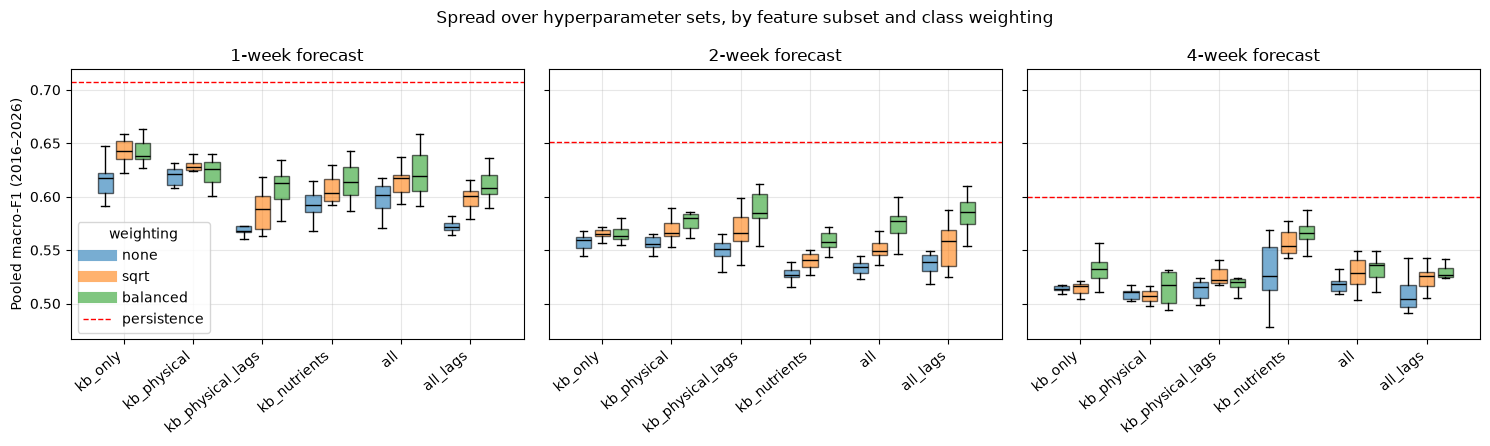

In [14]:
fig, axes = plt.subplots(1, len(HORIZONS), figsize=(15, 4.5), sharey=True)
for ax, horizon in zip(axes, HORIZONS):
    lb = leaderboard[leaderboard["horizon"] == horizon]
    order = list(FEATURE_SETS)
    for i, w in enumerate(["none", "sqrt", "balanced"]):
        vals = [lb[(lb["feature_set"] == fs) & (lb["weighting"] == w)]["macro_f1"] for fs in order]
        ax.boxplot(vals, positions=np.arange(len(order)) + (i - 1) * 0.27, widths=0.22,
                   patch_artist=True, boxprops=dict(facecolor=f"C{i}", alpha=0.6),
                   medianprops=dict(color="black"), showfliers=False)
        ax.plot([], [], color=f"C{i}", lw=8, alpha=0.6, label=w)
    persist = reference_summary[(reference_summary["horizon"] == horizon)
                                & reference_summary["model"].str.startswith("Persistence")]
    ax.axhline(persist["macro_f1"].iloc[0], color="red", ls="--", lw=1, label="persistence")
    ax.set_xticks(range(len(order)))
    ax.set_xticklabels(order, rotation=40, ha="right")
    ax.set_title(f"{horizon}-week forecast")
    ax.grid(alpha=0.3)
axes[0].set_ylabel("Pooled macro-F1 (2016–2026)")
axes[0].legend(title="weighting", loc="lower left")
plt.suptitle("Spread over hyperparameter sets, by feature subset and class weighting")
plt.tight_layout()
plt.show()

### Nested Forward-Chaining: Per-Horizon Tuning Without Peeking

For each horizon and each test year *Y*:

1. Score every configuration on the **earlier** folds only (2013 through *Y−1*). Validation weeks whose target date falls inside year *Y* are dropped.
2. Pick the configuration with the highest pooled macro-F1 on those earlier folds.
3. Use that configuration's forecasts for year *Y*.

Concatenating these forecasts gives an honest estimate of the whole tuning procedure for each horizon. The same procedure is also run with the search restricted to unweighted training, which isolates the effect of class weighting.

In [15]:
def inner_scores(preds_h, year):
    test_start = pd.Timestamp(year=year - 1, month=8, day=1)
    inner = preds_h[(preds_h["test_year"] < year) & (preds_h["target_week"] < test_start)]
    return inner.groupby("config_id").apply(
        lambda g: f1_score(g["y_true"], g["y_pred"], labels=CLASSES, average="macro",
                           zero_division=0),
        include_groups=False,
    )


def nested_selection(preds, allowed_configs=None, label="Tuned XGBoost (nested)"):
    selected, out = [], []
    for horizon in HORIZONS:
        preds_h = preds[preds["horizon"] == horizon]
        if allowed_configs is not None:
            preds_h = preds_h[preds_h["config_id"].isin(allowed_configs)]
        for year in TEST_YEARS:
            scores = inner_scores(preds_h, year)
            # Keep the original config order so ties resolve the same way every run
            scores = scores.reindex([c for c in cfg_meta.index if c in scores.index])
            best = scores.idxmax()
            selected.append({"horizon": horizon, "test_year": year, "config_id": best,
                             "inner_macro_f1": scores.max()})
            fold = preds_h[(preds_h["config_id"] == best) & (preds_h["test_year"] == year)]
            out.append(fold.assign(model=label))
    return pd.DataFrame(selected), pd.concat(out, ignore_index=True)


selected_all, nested_preds = nested_selection(search_preds)
unweighted_ids = cfg_meta.index[cfg_meta["weighting"] == "none"]
_, nested_unweighted = nested_selection(search_preds, unweighted_ids,
                                        label="Tuned XGBoost, unweighted only (nested)")

print("Configuration chosen for each test year (using earlier years only):")
display(selected_all.pivot(index="test_year", columns="horizon", values="config_id"))

Configuration chosen for each test year (using earlier years only):


horizon,1,2,4
test_year,,,
2016,kb_only|balanced|hp2,kb_only|balanced|hp3,all_lags|none|hp4
2017,kb_only|balanced|hp2,kb_only|balanced|hp9,kb_nutrients|balanced|hp0
2018,kb_only|balanced|hp0,kb_only|balanced|hp3,kb_only|balanced|hp8
2019,all|balanced|hp9,kb_only|balanced|hp3,kb_only|balanced|hp5
2020,all|balanced|hp9,kb_physical|balanced|hp5,kb_only|balanced|hp5
2021,all|balanced|hp9,kb_physical|balanced|hp5,kb_nutrients|balanced|hp9
2022,kb_only|balanced|hp9,kb_only|balanced|hp7,kb_only|balanced|hp5
2023,kb_only|balanced|hp9,kb_only|balanced|hp7,kb_only|balanced|hp5
2024,kb_only|balanced|hp9,kb_only|balanced|hp7,kb_only|balanced|hp5


### Final Comparison

All rows are scored on the same out-of-fold weeks from the 2016–2026 test years.

In [16]:
comparison_preds = pd.concat(
    [reference_preds, nested_unweighted.drop(columns="config_id"),
     nested_preds.drop(columns="config_id")],
    ignore_index=True,
)
comparison = pd.DataFrame([
    {"horizon": h, "model": m, **summarize(g)}
    for (h, m), g in comparison_preds.groupby(["horizon", "model"], sort=False)
])
comparison = comparison.sort_values(["horizon", "macro_f1"], ascending=[True, False])
display(comparison.round(3).reset_index(drop=True))

,horizon,model,macro_f1,accuracy,f1_c1,f1_c2,recall_c1,recall_c2,mean_year_macro_f1,n
0,1,Persistence (last_class),0.708,0.833,0.360,0.856,0.36,0.856,0.722,448
1,1,Tuned XGBoost (nested),0.634,0.810,0.195,0.805,0.16,0.839,0.557,448
2,1,"Tuned XGBoost, unweighted only (nested)",0.608,0.815,0.123,0.807,0.08,0.831,0.579,448
3,1,"Default XGBoost, all features",0.607,0.826,0.098,0.820,0.06,0.847,0.559,448
4,1,"Default XGBoost, fold top-15",0.587,0.828,0.037,0.824,0.02,0.831,0.619,448
5,2,Persistence (last_class),0.652,0.790,0.280,0.797,0.28,0.797,0.670,447
6,2,Tuned XGBoost (nested),0.557,0.720,0.108,0.713,0.12,0.737,0.501,447
7,2,"Tuned XGBoost, unweighted only (nested)",0.554,0.779,0.030,0.766,0.02,0.763,0.541,447
8,2,"Default XGBoost, all features",0.544,0.770,0.065,0.703,0.04,0.653,0.551,447
9,2,"Default XGBoost, fold top-15",0.514,0.740,0.031,0.670,0.02,0.627,0.458,447


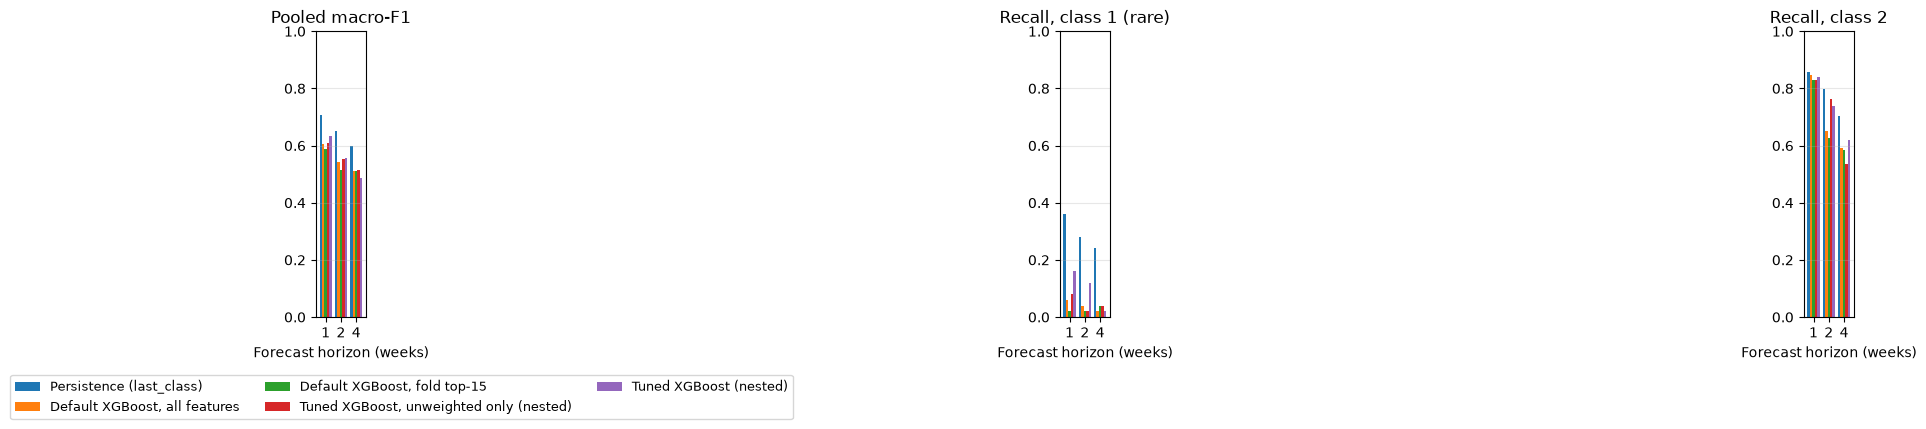

In [17]:
MODEL_ORDER = ["Persistence (last_class)", "Default XGBoost, all features",
               "Default XGBoost, fold top-15", "Tuned XGBoost, unweighted only (nested)",
               "Tuned XGBoost (nested)"]

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, metric, title in zip(axes, ["macro_f1", "recall_c1", "recall_c2"],
                             ["Pooled macro-F1", "Recall, class 1 (rare)", "Recall, class 2"]):
    pivot = comparison.pivot(index="horizon", columns="model", values=metric)[MODEL_ORDER]
    pivot.plot(kind="bar", ax=ax, rot=0, legend=False, width=0.8)
    ax.set_title(title)
    ax.set_xlabel("Forecast horizon (weeks)")
    ax.grid(axis="y", alpha=0.3)
    ax.set_ylim(0, 1)
axes[0].legend(loc="upper center", bbox_to_anchor=(1.7, -0.18), ncol=3, fontsize=9)
plt.tight_layout()
plt.show()

### Performance by Test Year

Per-year macro-F1 for the main models. Years with very few labelled weeks (2022 has n = 4, 2023 has n = 11) or only one class (2024, 2026) swing widely, which is why they are not used for model selection.

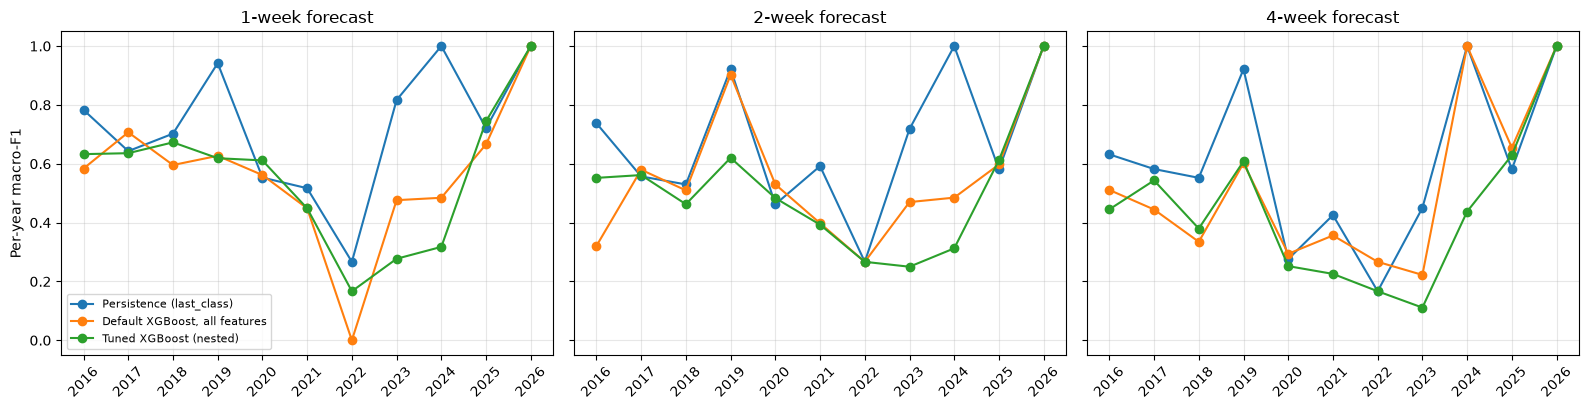

In [18]:
year_rows = []
for (h, m, y), g in comparison_preds.groupby(["horizon", "model", "test_year"]):
    year_rows.append({"horizon": h, "model": m, "test_year": y, "n": len(g),
                      "macro_f1": f1_score(g["y_true"], g["y_pred"], average="macro",
                                           zero_division=0)})
year_df = pd.DataFrame(year_rows)

plot_models = ["Persistence (last_class)", "Default XGBoost, all features", "Tuned XGBoost (nested)"]
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2), sharey=True)
for ax, horizon in zip(axes, HORIZONS):
    for m in plot_models:
        d = year_df[(year_df["horizon"] == horizon) & (year_df["model"] == m)].sort_values("test_year")
        ax.plot(d["test_year"], d["macro_f1"], marker="o", label=m)
    ax.set_title(f"{horizon}-week forecast")
    ax.set_xticks(TEST_YEARS)
    ax.tick_params(axis="x", rotation=45)
    ax.grid(alpha=0.3)
axes[0].set_ylabel("Per-year macro-F1")
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

### Confusion Matrices

Pooled out-of-fold confusion matrices for persistence and the nested-tuned model. Rows are true classes and columns are predicted classes.

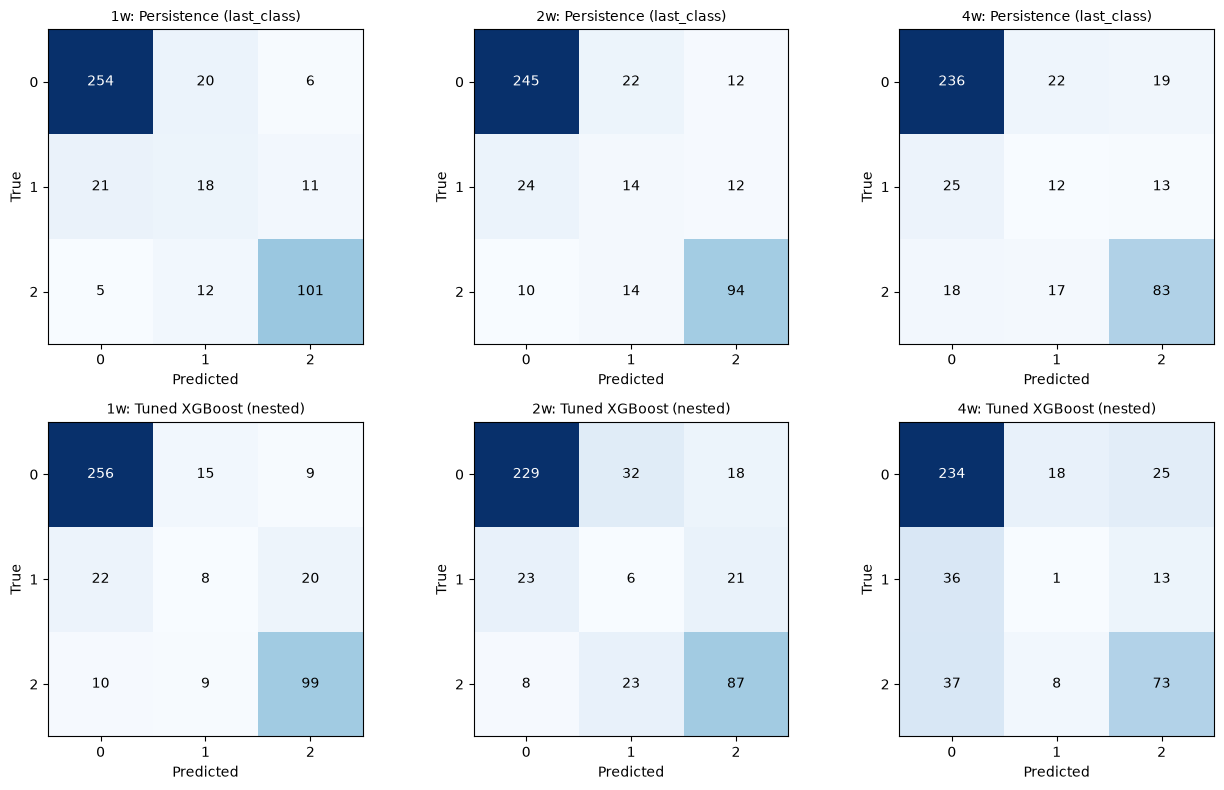

In [19]:
fig, axes = plt.subplots(2, 3, figsize=(13, 8))
for col, horizon in enumerate(HORIZONS):
    for row, m in enumerate(["Persistence (last_class)", "Tuned XGBoost (nested)"]):
        g = comparison_preds[(comparison_preds["horizon"] == horizon) & (comparison_preds["model"] == m)]
        cm = confusion_matrix(g["y_true"], g["y_pred"], labels=CLASSES)
        ax = axes[row, col]
        ax.imshow(cm, cmap="Blues")
        for i in range(3):
            for j in range(3):
                ax.text(j, i, cm[i, j], ha="center", va="center",
                        color="white" if cm[i, j] > cm.max() / 2 else "black")
        ax.set_xticks(CLASSES)
        ax.set_yticks(CLASSES)
        ax.set_xlabel("Predicted")
        ax.set_ylabel("True")
        ax.set_title(f"{horizon}w: {m}", fontsize=10)
plt.tight_layout()
plt.show()

### Final Per-Horizon Configurations

For deployment, each horizon's configuration is chosen with the same rule but using **all** folds through 2026. These settings are what a model forecasting the coming season would use. The scores beside them are in-sample with respect to the selection, so quote the nested results above, not these, as the expected performance.

In [20]:
final_configs = {}
for horizon in HORIZONS:
    # Same rule as the nested loop, extended to every fold from 2013 onward
    preds_h = search_preds[search_preds["horizon"] == horizon]
    all_scores = preds_h.groupby("config_id").apply(
        lambda g: f1_score(g["y_true"], g["y_pred"], labels=CLASSES, average="macro",
                           zero_division=0), include_groups=False)
    all_scores = all_scores.reindex(cfg_meta.index)
    best = all_scores.idxmax()
    cfg = next(c for c in CONFIGS if c["config_id"] == best)
    final_configs[horizon] = cfg
    print(f"{horizon}-week: {best}")
    print("   params:", cfg["params"] if cfg["params"] else "XGBoost defaults",
          f"| in-sample pooled macro-F1 (2013-2026): {all_scores[best]:.3f}")

with open(os.path.join(RESULTS_DIR, "final_xgb_configs.json"), "w") as f:
    json.dump({f"{h}w": {k: v for k, v in c.items()} for h, c in final_configs.items()},
              f, indent=2, default=str)

1-week: kb_only|balanced|hp9
   params: {'subsample': 0.85, 'reg_lambda': 1, 'n_estimators': 100, 'min_child_weight': 1, 'max_depth': 4, 'learning_rate': 0.1, 'gamma': 0.5, 'colsample_bytree': 0.6} | in-sample pooled macro-F1 (2013-2026): 0.641


2-week: kb_physical_lags|balanced|hp0
   params: XGBoost defaults | in-sample pooled macro-F1 (2013-2026): 0.583


4-week: kb_nutrients|balanced|hp0
   params: XGBoost defaults | in-sample pooled macro-F1 (2013-2026): 0.571


### Feature Importance of the Final Models

Each horizon's final configuration is refit on all labelled weeks, and its top features are plotted by gain. Gain importance shows what the model relied on. It does not show cause and effect.

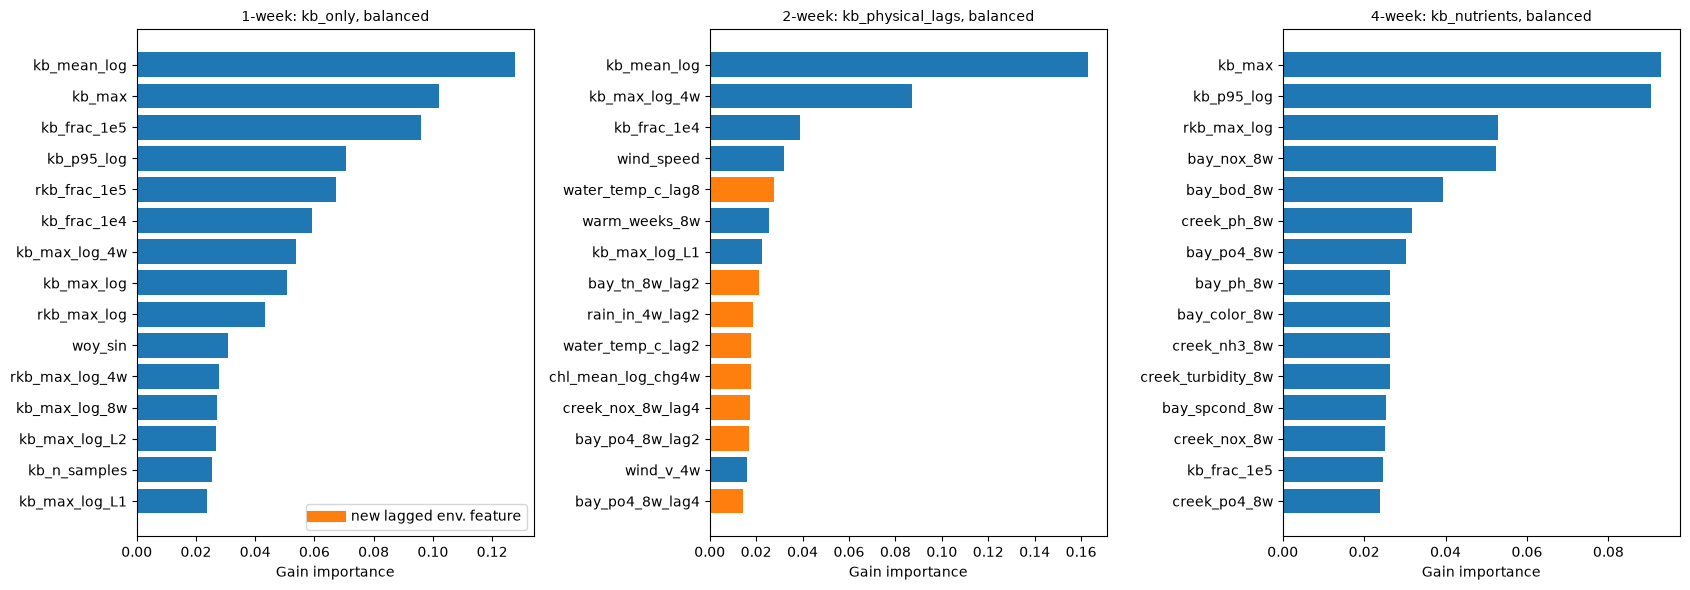

In [21]:
final_models = {}
fig, axes = plt.subplots(1, 3, figsize=(17, 6))
for ax, horizon in zip(axes, HORIZONS):
    data, target = horizon_data(horizon)
    cfg = final_configs[horizon]
    feats = FEATURE_SETS[cfg["feature_set"]]
    model = XGBClassifier(**BASE_PARAMS, **cfg["params"])
    model.fit(data[feats], data[target], sample_weight=sample_weights(data[target], cfg["weighting"]))
    final_models[horizon] = model
    imp = pd.Series(model.feature_importances_, index=feats).nlargest(15).sort_values()
    colors = ["C1" if f in ENV_LAG_COLS else "C0" for f in imp.index]
    ax.barh(imp.index, imp.values, color=colors)
    ax.set_title(f"{horizon}-week: {cfg['feature_set']}, {cfg['weighting']}", fontsize=10)
    ax.set_xlabel("Gain importance")
axes[0].plot([], [], color="C1", lw=8, label="new lagged env. feature")
axes[0].legend(loc="lower right")
plt.tight_layout()
plt.show()

### Save the Final Models for Reproducibility

Each horizon's fitted model is written to `results/models/` in XGBoost's native JSON format. This format stores every tree, split and leaf weight, and it loads across XGBoost versions. A metadata file is saved alongside each model with:

* the exact feature columns, in the order the model expects
* the hyperparameters, class-weighting scheme, seed and training period
* the per-class sample weights used in training
* the library versions
* a SHA-256 checksum of the input data

The final cell reloads each model and confirms that its predictions match the in-memory model exactly.

In [22]:
import pickle
import platform
import sklearn
import xgboost

MODEL_DIR = os.path.join(RESULTS_DIR, "models")
os.makedirs(MODEL_DIR, exist_ok=True)

with open(DATA_PATH, "rb") as f:
    data_sha256 = hashlib.sha256(f.read()).hexdigest()

for horizon, model in final_models.items():
    data, target = horizon_data(horizon)
    cfg = final_configs[horizon]
    feats = FEATURE_SETS[cfg["feature_set"]]

    model_path = os.path.join(MODEL_DIR, f"xgb_{horizon}w.json")
    model.save_model(model_path)

    y = data[target]
    w = sample_weights(y, cfg["weighting"])
    class_weights = ({int(c): 1.0 for c in CLASSES} if w is None else
                     pd.Series(w, index=y.index).groupby(y).first().round(6).to_dict())

    metadata = {
        "horizon_weeks": horizon,
        "target": target,
        "config_id": cfg["config_id"],
        "feature_set": cfg["feature_set"],
        "features": feats,
        "class_weighting": cfg["weighting"],
        "class_sample_weights": {int(k): float(v) for k, v in class_weights.items()},
        "hyperparameters": {**BASE_PARAMS, **cfg["params"]},
        "seed": SEED,
        "n_training_rows": int(len(data)),
        "training_period": [str(data["week_ending"].min().date()),
                            str(data["week_ending"].max().date())],
        "env_lag_vars": LAG_VARS, "env_lags": LAGS,
        "data_file": DATA_PATH, "data_sha256": data_sha256,
        "versions": {"xgboost": xgboost.__version__, "scikit-learn": sklearn.__version__,
                     "pandas": pd.__version__, "numpy": np.__version__,
                     "python": platform.python_version()},
    }
    with open(os.path.join(MODEL_DIR, f"xgb_{horizon}w_metadata.json"), "w") as f:
        json.dump(metadata, f, indent=2)

    # Pickle bundle: the fitted model plus everything needed to use it
    pickle_path = os.path.join(MODEL_DIR, f"xgb_{horizon}w.pkl")
    with open(pickle_path, "wb") as f:
        pickle.dump({"model": model, **metadata}, f, protocol=pickle.HIGHEST_PROTOCOL)

    print(f"Saved {pickle_path} and {model_path}  "
          f"({len(feats)} features, weighting = {cfg['weighting']})")

Saved results\models\xgb_1w.pkl and results\models\xgb_1w.json  (25 features, weighting = balanced)
Saved results\models\xgb_2w.pkl and results\models\xgb_2w.json  (114 features, weighting = balanced)
Saved results\models\xgb_4w.pkl and results\models\xgb_4w.json  (55 features, weighting = balanced)


**Loading a saved model.** Unpickle the bundle and select `bundle["features"]` in the stored order:

```python
with open("results/models/xgb_1w.pkl", "rb") as f:
    bundle = pickle.load(f)
predictions = bundle["model"].predict(new_data[bundle["features"]])
```

A pickle should be loaded with the same XGBoost version it was saved with, which is recorded in `bundle["versions"]`. The `.json` copy works across versions if they differ. Only unpickle files you created yourself, because loading a pickle can run arbitrary code.

In [23]:
# Reload each pickle (and JSON copy) and confirm it reproduces the in-memory predictions
for horizon in HORIZONS:
    with open(os.path.join(MODEL_DIR, f"xgb_{horizon}w.pkl"), "rb") as f:
        bundle = pickle.load(f)
    from_json = XGBClassifier()
    from_json.load_model(os.path.join(MODEL_DIR, f"xgb_{horizon}w.json"))

    data, _ = horizon_data(horizon)
    X = data[bundle["features"]]
    expected = final_models[horizon].predict_proba(X)
    same_pkl = np.allclose(bundle["model"].predict_proba(X), expected)
    same_json = np.allclose(from_json.predict_proba(X), expected)
    print(f"{horizon}-week: pickle identical = {same_pkl}, JSON identical = {same_json}")
    assert same_pkl and same_json

1-week: pickle identical = True, JSON identical = True


2-week: pickle identical = True, JSON identical = True
4-week: pickle identical = True, JSON identical = True


## Conclusion

**Pooled macro-F1 on the 2016–2026 test years** (n ≈ 445 weeks per horizon):

| Horizon | Persistence | Default XGBoost (first version) | Tuned XGBoost, nested (honest) | Best single config (optimistic) |
| --- | --- | --- | --- | --- |
| 1 week | **0.708** | 0.607 | 0.634 | 0.676 |
| 2 weeks | **0.652** | 0.544 | 0.557 | 0.612 |
| 4 weeks | **0.600** | 0.509 | 0.488 | 0.588 |

**1. Persistence is still the model to beat, and no XGBoost variant beats it.** Persistence simply repeats the last observed class. It wins at every horizon, including over the best configuration picked with hindsight. The gap is largest for class 1: persistence recalls 36% of class-1 weeks at 1 week, while XGBoost recalls 2–16%. The trees mostly learn "same class as now" and then miss the transitions that persistence partly captures. The first version's 74% accuracy is therefore not evidence of skill on its own; persistence reaches 83% at 1 week.

**2. Tuning each horizon separately helped at 1 and 2 weeks but not at 4 weeks.** Honest nested macro-F1 went from 0.607 to 0.634 at 1 week and from 0.544 to 0.557 at 2 weeks. At 4 weeks it fell from 0.509 to 0.488. The chosen configuration changes from year to year at every horizon, and at 4 weeks the earlier years were too few and too noisy to pick a configuration that holds up. The horizons favour different setups:
* 1 week: K. brevis history only, with shallow, fast-learning trees (`max_depth=4`, `n_estimators=100`).
* 2 weeks: K. brevis history plus physical drivers and their lags.
* 4 weeks: K. brevis history plus nutrients.

**3. Class-balanced training is the most consistent improvement.** Balanced weights raise the median macro-F1 at every horizon (1w: 0.593 → 0.619, 2w: 0.545 → 0.574, 4w: 0.514 → 0.529), and 32 of the 33 nested picks used balanced weights. Class-1 recall rises from 0–4% to 5–16%, at a cost of 1–3 points of accuracy. Square-root weights land in between. Weighting alone still does not recover class 1 to persistence's level.

**4. Feature subsets and lagged environmental variables give mixed results.** At 1 week the K. brevis-only subset (25 features) does best, and adding the environmental lags *lowers* the median score. At 2 weeks the lags help slightly when combined with balanced weights (0.585 vs 0.580), and the top configurations use them. At 4 weeks the nutrient subset is clearly best, which fits nutrient loading acting on longer timescales. With about 450 test weeks and 50 class-1 test weeks, differences of 0.01–0.02 are within noise.

**5. Recommended next steps**
* Model change rather than state: predict whether the class will move up or down from `last_class`, or blend XGBoost probabilities with the persistence forecast.
* Tune a decision threshold for class 1 on inner folds rather than relying on `argmax`.
* Treat the classes as ordinal, or merge class 1 into a binary "bloom ≥ class 1" task to check whether the rare class is learnable at all.
* Report bootstrap confidence intervals on pooled macro-F1, because test years such as 2022 (n = 4) and 2023 (n = 11) are very small.

The final per-horizon models are saved in `results/models/` as pickle files, with JSON copies and metadata for reproducibility.

## Resources
1. https://machinelearningmastery.com/develop-first-xgboost-model-python-scikit-learn/
2. XGBoost parameter reference: https://xgboost.readthedocs.io/en/stable/parameter.html
3. scikit-learn, class-balanced sample weights: https://scikit-learn.org/stable/modules/generated/sklearn.utils.class_weight.compute_sample_weight.html